# Benchmark Final — BGE-M3 Fine-tuned vs Base Ampara AI

Este notebook asume que ya tienes:
- El modelo fine-tuneado guardado en Drive (`modelo_final/`)
- Los archivos de evaluación corregidos (`corpus_fixed.jsonl`, `test_qrels_fixed.jsonl`)
- Las variables `base_metrics` y `ft_final_metrics` del notebook de entrenamiento

Si vienes de una sesión nueva, ejecuta las secciones 0-3 para recargar todo desde Drive.

## 0. Setup — Instalar dependencias y montar Drive

In [ ]:
!pip install -q FlagEmbedding faiss-cuda pytrec_eval datasets transformers

from google.colab import drive
drive.mount('/content/drive')
print('✓ Drive montado')

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.7/247.7 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 407.7/407.7 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 107.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.1/866.1 kB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.7/149.7 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 133.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 83.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 45.2 MB/s eta 0:00:00
Mounted at /content/drive
✓ Drive montado


## 1. Configuración de rutas

In [ ]:
import os, json, torch, gc
import numpy as np
import faiss
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from pathlib import Path
from collections import defaultdict
from tqdm.notebook import tqdm
from datasets import load_dataset
from FlagEmbedding import BGEM3FlagModel
from FlagEmbedding.abc.evaluation.utils import evaluate_metrics, evaluate_mrr

# ── Rutas ────────────────────────────────────────────────────────
DRIVE_BASE    = Path("/content/drive/MyDrive/bge-m3-legal-peru-2048")
FT_MODEL_PATH = str(DRIVE_BASE / "modelo_final")   # modelo fine-tuned
BASE_MODEL    = "BAAI/bge-m3"

# Archivos de evaluación — ajusta si están en otra ubicación
CORPUS_FIXED  = Path("/content/corpus_fixed.jsonl")
QUERIES_FILE  = Path("/content/test_queries.jsonl")
QRELS_FIXED   = Path("/content/test_qrels_fixed.jsonl")

# Si los archivos corregidos no están en /content, cópialos desde Drive
# (solo si los guardaste allá en la sesión anterior)
for fname in ["corpus_fixed.jsonl", "test_qrels_fixed.jsonl", "test_queries.jsonl"]:
    src = DRIVE_BASE / fname
    dst = Path("/content") / fname
    if not dst.exists() and src.exists():
        import shutil
        shutil.copy2(src, dst)
        print(f"  ✓ Copiado desde Drive: {fname}")

K_VALUES = [10, 100]

# Paleta de colores
C_BASE  = "#94A3B8"
C_FINAL = "#1D4ED8"
C_POS   = "#16A34A"
C_NEG   = "#DC2626"

print(f"Modelo fine-tuned : {FT_MODEL_PATH}")
print(f"Modelo base       : {BASE_MODEL}")
print(f"GPU               : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

Modelo fine-tuned : /content/drive/MyDrive/bge-m3-legal-peru-2048/modelo_final
Modelo base       : BAAI/bge-m3
GPU               : NVIDIA L4


## 2. Funciones de evaluación

In [ ]:
def load_eval_data(corpus_file, queries_file, qrels_file):
    queries_ds = load_dataset("json", data_files=str(queries_file))["train"]
    corpus_ds  = load_dataset("json", data_files=str(corpus_file))["train"]
    qrels_ds   = load_dataset("json", data_files=str(qrels_file))["train"]

    queries_text = queries_ds["text"]
    corpus_text  = []
    for item in corpus_ds["text"]:
        corpus_text.extend(item) if isinstance(item, list) else corpus_text.append(item)

    qrels_dict = defaultdict(dict)
    for row in qrels_ds:
        qrels_dict[str(row["qid"])][str(row["docid"])] = int(row["relevance"])

    print(f"  Queries : {len(queries_text)}")
    print(f"  Corpus  : {len(corpus_text)} documentos")
    print(f"  Qrels   : {len(qrels_dict)} queries anotadas")
    return queries_ds, corpus_ds, queries_text, corpus_text, qrels_dict


def encode_and_search(model, queries_ds, corpus_ds,
                      queries_text, corpus_text, k=100, batch_size=32):
    print(f"  Codificando {len(queries_text)} queries...")
    q_out = model.encode(queries_text, batch_size=batch_size,
                         max_length=2048, return_dense=True)
    queries_emb = np.array(q_out["dense_vecs"], dtype=np.float32)

    print(f"  Codificando {len(corpus_text)} documentos...")
    c_out = model.encode(corpus_text, batch_size=batch_size,
                         max_length=2048, return_dense=True)
    corpus_emb = np.array(c_out["dense_vecs"], dtype=np.float32)

    dim   = corpus_emb.shape[-1]
    index = faiss.index_factory(dim, "Flat", faiss.METRIC_INNER_PRODUCT)
    index.train(corpus_emb)
    index.add(corpus_emb)

    print(f"  Buscando top-{k}...")
    all_scores, all_indices = [], []
    for i in tqdm(range(0, len(queries_emb), batch_size), desc="  Searching"):
        j = min(i + batch_size, len(queries_emb))
        scores, indices = index.search(queries_emb[i:j], k=k)
        all_scores.append(scores)
        all_indices.append(indices)

    all_scores  = np.concatenate(all_scores,  axis=0)
    all_indices = np.concatenate(all_indices, axis=0)

    results = {}
    for idx, (scores, indices) in enumerate(zip(all_scores, all_indices)):
        qid = str(queries_ds["id"][idx])
        results[qid] = {}
        for score, doc_idx in zip(scores, indices):
            if doc_idx != -1:
                results[qid][str(corpus_ds["id"][int(doc_idx)])] = float(score)
    return results


def run_eval(model, label, queries_ds, corpus_ds,
             queries_text, corpus_text, qrels_dict, k_values, batch_size=32):
    print(f"\n{'─'*55}")
    print(f"  Evaluando: {label}")
    print(f"{'─'*55}")
    results  = encode_and_search(model, queries_ds, corpus_ds,
                                 queries_text, corpus_text,
                                 k=max(k_values), batch_size=batch_size)
    eval_res = evaluate_metrics(qrels_dict, results, k_values)
    mrr_res  = evaluate_mrr(qrels_dict, results, k_values)

    all_metrics = {}
    print(f"\n  Métricas:")
    for md in eval_res:
        for key, val in md.items():
            print(f"    {key:<20} {val:.5f}")
            all_metrics[key] = val
    for key, val in mrr_res.items():
        print(f"    {key:<20} {val:.5f}")
        all_metrics[key] = val
    return all_metrics


print("✓ Funciones de evaluación listas.")

✓ Funciones de evaluación listas.


# CORRECCION DATASET PARA EVALUACION

In [ ]:
from datasets import load_dataset
from collections import defaultdict
import json
from pathlib import Path

# Archivos originales (deben estar en /content)
TRAINING_FILE = Path("/content/training.json")
CORPUS_FILE   = Path("/content/corpus.jsonl")
QUERIES_FILE  = Path("/content/test_queries.jsonl")
QRELS_FILE    = Path("/content/test_qrels.jsonl")

# Archivos corregidos (salida)
CORPUS_FIXED  = Path("/content/corpus_fixed.jsonl")
QRELS_FIXED   = Path("/content/test_qrels_fixed.jsonl")

# ── 1. Leer training para construir corpus base ──────────────────
train_samples = []
with open(TRAINING_FILE, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            train_samples.append(json.loads(line))

corpus_new = {}
for s in train_samples:
    sid  = str(s["id"])
    pos  = s["pos"]
    text = pos[0] if isinstance(pos, list) else pos
    if sid not in corpus_new:
        corpus_new[sid] = text

print(f"Corpus desde training : {len(corpus_new)} documentos")

# ── 2. Agregar positivos de las queries de test ──────────────────
test_queries_ds = load_dataset("json", data_files=str(QUERIES_FILE))["train"]
qrels_ds_orig   = load_dataset("json", data_files=str(QRELS_FILE))["train"]
corpus_ds_orig  = load_dataset("json", data_files=str(CORPUS_FILE))["train"]

id_to_text_orig = {str(r["id"]): r["text"] for r in corpus_ds_orig}

qid_to_docids = defaultdict(list)
for row in qrels_ds_orig:
    qid_to_docids[str(row["qid"])].append(str(row["docid"]))

for row in test_queries_ds:
    qid = str(row["id"])
    if qid not in corpus_new:
        for docid in qid_to_docids.get(qid, []):
            if docid in id_to_text_orig:
                corpus_new[qid] = id_to_text_orig[docid]
                break

print(f"Corpus total          : {len(corpus_new)} documentos")

# ── 3. Guardar corpus corregido ──────────────────────────────────
with open(CORPUS_FIXED, "w", encoding="utf-8") as f:
    for sid, text in corpus_new.items():
        f.write(json.dumps({"id": sid, "text": text}, ensure_ascii=False) + "\n")

# ── 4. Qrels corregidos: qid → qid (ID simple) ──────────────────
qrels_new = []
missing   = []
for row in test_queries_ds:
    qid = str(row["id"])
    if qid in corpus_new:
        qrels_new.append({"qid": qid, "docid": qid, "relevance": 1})
    else:
        missing.append(qid)

if missing:
    print(f"⚠️  {len(missing)} queries sin positivo: {missing[:5]}")

with open(QRELS_FIXED, "w", encoding="utf-8") as f:
    for item in qrels_new:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# ── 5. Verificación ──────────────────────────────────────────────
corpus_ids  = set(corpus_new.keys())
qrel_docids = {r["docid"] for r in qrels_new}
overlap     = corpus_ids & qrel_docids

print(f"\nQueries         : {len(test_queries_ds)}")
print(f"Docs en corpus  : {len(corpus_ids)}")
print(f"Qrels           : {len(qrels_new)}")
print(f"Overlap docids  : {len(overlap)} de {len(qrel_docids)}")
print(f"\n{'✓ IDs consistentes — listo para evaluar' if len(overlap) == len(qrel_docids) else '✗ Aún hay IDs sin match'}")

Corpus desde training : 810 documentos


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Corpus total          : 900 documentos

Queries         : 90
Docs en corpus  : 900
Qrels           : 90
Overlap docids  : 90 de 90

✓ IDs consistentes — listo para evaluar


## 3. Cargar datos de evaluación

In [ ]:
print("Cargando datos de evaluación...")
queries_ds, corpus_ds, queries_text, corpus_text, qrels_dict = load_eval_data(
    CORPUS_FIXED, QUERIES_FILE, QRELS_FIXED
)

Cargando datos de evaluación...


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

  Queries : 90
  Corpus  : 900 documentos
  Qrels   : 90 queries anotadas


## 4. Evaluar modelo BASE

In [ ]:
print(f"Cargando {BASE_MODEL}...")
base_model = BGEM3FlagModel(BASE_MODEL, use_fp16=True)

base_metrics = run_eval(
    base_model, f"BASE — {BASE_MODEL}",
    queries_ds, corpus_ds, queries_text, corpus_text,
    qrels_dict, K_VALUES, batch_size=32,
)

del base_model
gc.collect()
torch.cuda.empty_cache()
print("\n✓ Memoria GPU liberada.")

Cargando BAAI/bge-m3...


Fetching 30 files:   0%|          | 0/30 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


───────────────────────────────────────────────────────
  Evaluando: BASE — BAAI/bge-m3
───────────────────────────────────────────────────────
  Codificando 90 queries...


Inference Embeddings: 100%|██████████| 3/3 [00:00<00:00, 51.03it/s]


  Codificando 900 documentos...


Inference Embeddings: 100%|██████████| 29/29 [00:12<00:00,  2.36it/s]

  Buscando top-100...


  Searching:   0%|          | 0/3 [00:00<?, ?it/s]


  Métricas:
    NDCG@10              0.07809
    NDCG@100             0.13060
    MAP@10               0.06446
    MAP@100              0.07237
    Recall@10            0.12222
    Recall@100           0.40000
    P@10                 0.01222
    P@100                0.00400
    MRR@10               0.09466
    MRR@100              0.10240

✓ Memoria GPU liberada.


## 5. Evaluar modelo FINE-TUNED (checkpoint final)

In [ ]:
print(f"Cargando modelo fine-tuned desde Drive...\n  {FT_MODEL_PATH}")
ft_model = BGEM3FlagModel(FT_MODEL_PATH, use_fp16=True)

ft_final_metrics = run_eval(
    ft_model, "FINE-TUNED — BGE-M3 Legal Perú (checkpoint final)",
    queries_ds, corpus_ds, queries_text, corpus_text,
    qrels_dict, K_VALUES, batch_size=32,
)

del ft_model
gc.collect()
torch.cuda.empty_cache()
print("\n✓ Memoria GPU liberada.")

Cargando modelo fine-tuned desde Drive...
  /content/drive/MyDrive/bge-m3-legal-peru-2048/modelo_final


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


───────────────────────────────────────────────────────
  Evaluando: FINE-TUNED — BGE-M3 Legal Perú (checkpoint final)
───────────────────────────────────────────────────────
  Codificando 90 queries...


Inference Embeddings: 100%|██████████| 3/3 [00:00<00:00, 50.22it/s]


  Codificando 900 documentos...


Inference Embeddings: 100%|██████████| 29/29 [00:12<00:00,  2.37it/s]

  Buscando top-100...


  Searching:   0%|          | 0/3 [00:00<?, ?it/s]


  Métricas:
    NDCG@10              0.11184
    NDCG@100             0.18792
    MAP@10               0.08475
    MAP@100              0.09608
    Recall@10            0.20000
    Recall@100           0.60000
    P@10                 0.02000
    P@100                0.00600
    MRR@10               0.14254
    MRR@100              0.15704

✓ Memoria GPU liberada.


## 6. Tabla comparativa completa

In [ ]:
metricas_orden = [
    "NDCG@10", "NDCG@100",
    "Recall@10", "Recall@100",
    "MRR@10", "MRR@100",
    "MAP@10", "MAP@100",
    "P@10", "P@100",
]

print(f"\n{'='*72}")
print(f"  BENCHMARK FINAL — BGE-M3 Base vs Fine-tuned (Legal Perú)")
print(f"  Corpus: 628 fragmentos | Test: 90 queries | MAX_LEN=2048")
print(f"{'='*72}")
print(f"  {'Métrica':<20} {'Base':>10} {'Fine-tuned':>12} {'Delta':>9} {'Mejora':>9}")
print(f"  {'─'*20} {'─'*10} {'─'*12} {'─'*9} {'─'*9}")

for key in metricas_orden:
    if key not in base_metrics:
        continue
    b   = base_metrics.get(key, 0.0)
    ft  = ft_final_metrics.get(key, 0.0)
    d   = ft - b
    pct = (d / b * 100) if b > 0 else 0.0
    arrow = "↑" if d > 0 else ("↓" if d < 0 else "=")
    print(f"  {key:<20} {b:>10.5f} {ft:>12.5f} {arrow}{abs(d):>7.5f} {pct:>+8.1f}%")

print(f"{'='*72}")

# Resumen ejecutivo
recall10_mejora = ((ft_final_metrics.get('Recall@10',0) - base_metrics.get('Recall@10',0))
                   / base_metrics.get('Recall@10',1) * 100)
mrr10_mejora   = ((ft_final_metrics.get('MRR@10',0) - base_metrics.get('MRR@10',0))
                   / base_metrics.get('MRR@10',1) * 100)
ndcg10_mejora  = ((ft_final_metrics.get('NDCG@10',0) - base_metrics.get('NDCG@10',0))
                   / base_metrics.get('NDCG@10',1) * 100)

print(f"\n  Resumen ejecutivo:")
print(f"    Recall@10  : {recall10_mejora:+.1f}%  ← métrica crítica para RAG")
print(f"    MRR@10     : {mrr10_mejora:+.1f}%  ← posición del primer hit correcto")
print(f"    NDCG@10    : {ndcg10_mejora:+.1f}%  ← calidad del ranking")


  BENCHMARK FINAL — BGE-M3 Base vs Fine-tuned (Legal Perú)
  Corpus: 628 fragmentos | Test: 90 queries | MAX_LEN=2048
  Métrica                    Base   Fine-tuned     Delta    Mejora
  ──────────────────── ────────── ──────────── ───────── ─────────
  NDCG@10                 0.07809      0.11184 ↑0.03375    +43.2%
  NDCG@100                0.13060      0.18792 ↑0.05732    +43.9%
  Recall@10               0.12222      0.20000 ↑0.07778    +63.6%
  Recall@100              0.40000      0.60000 ↑0.20000    +50.0%
  MRR@10                  0.09466      0.14254 ↑0.04788    +50.6%
  MRR@100                 0.10240      0.15704 ↑0.05464    +53.4%
  MAP@10                  0.06446      0.08475 ↑0.02029    +31.5%
  MAP@100                 0.07237      0.09608 ↑0.02371    +32.8%
  P@10                    0.01222      0.02000 ↑0.00778    +63.7%
  P@100                   0.00400      0.00600 ↑0.00200    +50.0%

  Resumen ejecutivo:
    Recall@10  : +63.6%  ← métrica crítica para RAG
    MRR@10   

## 7. Gráfico 1 — Curva de loss del entrenamiento

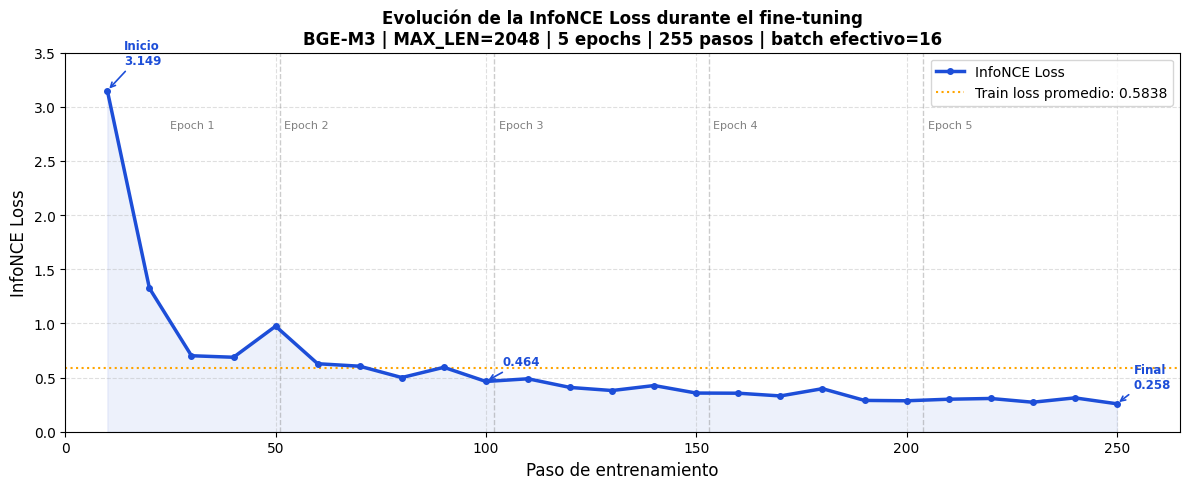

✓ loss_curve.png


In [ ]:
# ── GRÁFICO 1: Curva de loss CORREGIDA con valores reales ───────
pasos = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100,
         110, 120, 130, 140, 150, 160, 170, 180, 190, 200,
         210, 220, 230, 240, 250]

loss  = [3.149, 1.325, 0.7015, 0.6875, 0.9744, 0.6278, 0.6048, 0.5001, 0.5947, 0.464,
         0.4888, 0.4088, 0.3803, 0.4264, 0.357, 0.3556, 0.3304, 0.3974, 0.2891, 0.2857,
         0.3001, 0.3069, 0.2723, 0.3126, 0.258]

# Epochs aproximados (51 pasos por epoch)
epoch_steps = [51, 102, 153, 204]
epoch_labels = ['Epoch 2', 'Epoch 3', 'Epoch 4', 'Epoch 5']

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pasos, loss, marker='o', linewidth=2.5,
        color=C_FINAL, markersize=4, zorder=3, label='InfoNCE Loss')
ax.fill_between(pasos, loss, alpha=0.08, color=C_FINAL)

# Anotar puntos clave
for p, l, label in [(10, 3.149, 'Inicio\n3.149'),
                    (100, 0.464, '0.464'),
                    (250, 0.258, 'Final\n0.258')]:
    offset_x = 4
    offset_y = 0.15 if l < 2 else 0.25
    ax.annotate(label, xy=(p, l),
                xytext=(p + offset_x, l + offset_y),
                fontsize=8.5, color=C_FINAL, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=C_FINAL, lw=1.2))

# Separadores de epoch
for step, label in zip(epoch_steps, epoch_labels):
    ax.axvline(step, color='gray', linestyle='--', alpha=0.4, linewidth=1)
    ax.text(step + 1, 2.8, label, fontsize=8, color='gray')

# Epoch 1 label
ax.text(25, 2.8, 'Epoch 1', fontsize=8, color='gray')

# Train loss promedio final
ax.axhline(0.5838, color='orange', linestyle=':', linewidth=1.5,
           label=f'Train loss promedio: 0.5838')

ax.set_xlabel("Paso de entrenamiento", fontsize=12)
ax.set_ylabel("InfoNCE Loss", fontsize=12)
ax.set_title("Evolución de la InfoNCE Loss durante el fine-tuning\n"
             "BGE-M3 | MAX_LEN=2048 | 5 epochs | 255 pasos | batch efectivo=16",
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.4)
ax.set_xlim(0, 265)
ax.set_ylim(0, 3.5)
plt.tight_layout()
plt.savefig("/content/loss_curve.png", dpi=150, bbox_inches='tight')
plt.show()
print("✓ loss_curve.png")

## 8. Gráfico 2 — Barras comparativas Base vs Fine-tuned

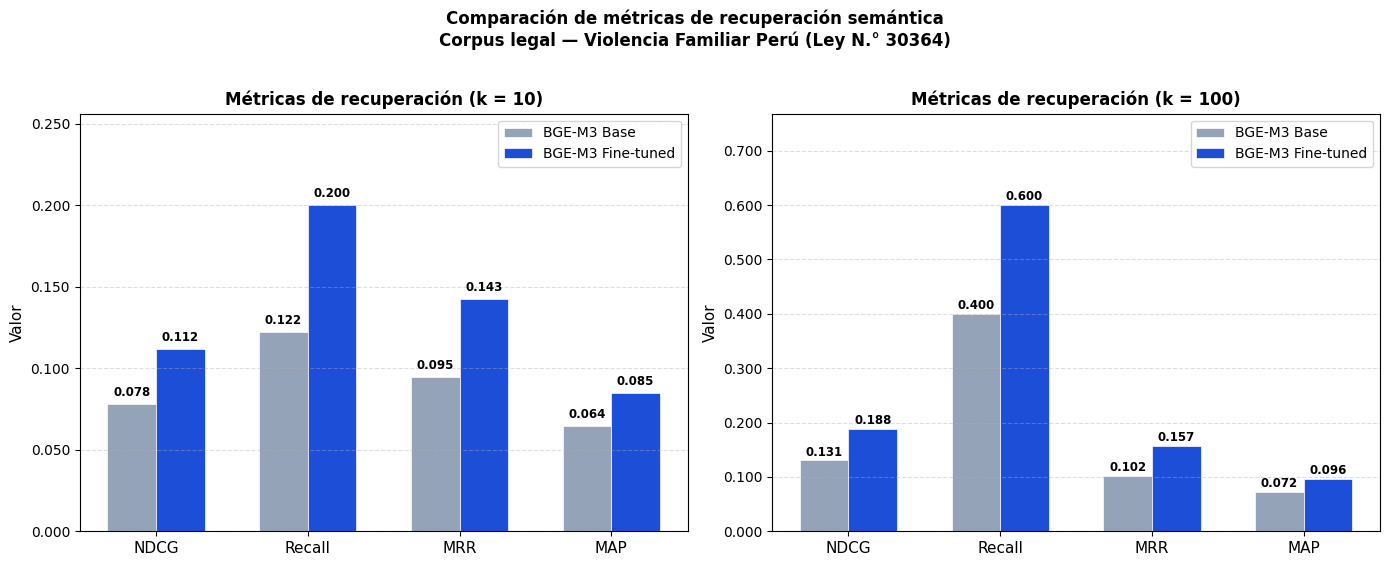

✓ metrics_comparison.png


In [ ]:
grupos = {
    "k = 10":  ["NDCG@10",  "Recall@10",  "MRR@10",  "MAP@10"],
    "k = 100": ["NDCG@100", "Recall@100", "MRR@100", "MAP@100"],
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (titulo, metricas) in zip(axes, grupos.items()):
    x     = np.arange(len(metricas))
    width = 0.32

    b_vals  = [base_metrics.get(m, 0)       for m in metricas]
    ff_vals = [ft_final_metrics.get(m, 0)   for m in metricas]

    b1 = ax.bar(x - width/2, b_vals,  width, label='BGE-M3 Base',
                color=C_BASE,  edgecolor='white', linewidth=0.5)
    b2 = ax.bar(x + width/2, ff_vals, width, label='BGE-M3 Fine-tuned',
                color=C_FINAL, edgecolor='white', linewidth=0.5)

    for bars in [b1, b2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.003,
                    f'{h:.3f}', ha='center', va='bottom', fontsize=8.5,
                    fontweight='bold')

    ax.set_title(f"Métricas de recuperación ({titulo})",
                 fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([m.split('@')[0] for m in metricas], fontsize=11)
    ax.set_ylabel("Valor", fontsize=11)
    ax.legend(fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_ylim(0, max(ff_vals) * 1.28)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

plt.suptitle("Comparación de métricas de recuperación semántica\n"
             "Corpus legal — Violencia Familiar Perú (Ley N.° 30364)",
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("/content/metrics_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("✓ metrics_comparison.png")

## 9. Gráfico 3 — Mejora porcentual

/tmp/ipykernel_567/2514718262.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(metricas_plot, rotation=20, ha='right', fontsize=10)


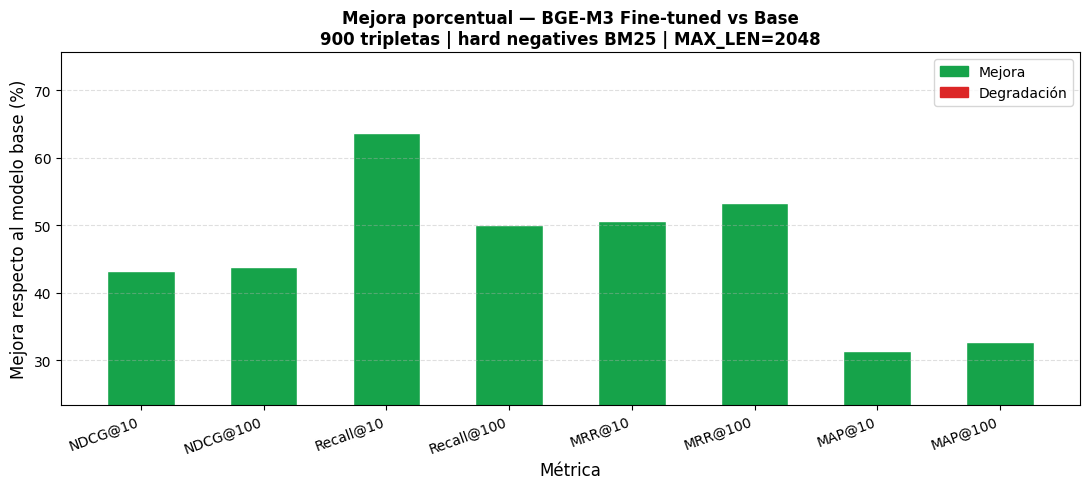

✓ improvement_pct.png


In [ ]:
metricas_plot = ["NDCG@10","NDCG@100","Recall@10","Recall@100",
                 "MRR@10","MRR@100","MAP@10","MAP@100"]

mejoras = []
for m in metricas_plot:
    b = base_metrics.get(m, 0)
    f = ft_final_metrics.get(m, 0)
    mejoras.append(((f - b) / b * 100) if b > 0 else 0)

fig, ax = plt.subplots(figsize=(11, 5))
colores = [C_POS if v >= 0 else C_NEG for v in mejoras]
bars = ax.bar(metricas_plot, mejoras, color=colores,
              edgecolor='white', width=0.55)

for bar, val in zip(bars, mejoras):
    offset = 0.8 if val >= 0 else -2.0
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + offset,
            f'{val:+.1f}%',
            ha='center', va='bottom',
            fontsize=10, fontweight='bold',
            color='white' if abs(val) > 15 else '#1e293b')

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel("Métrica", fontsize=12)
ax.set_ylabel("Mejora respecto al modelo base (%)", fontsize=12)
ax.set_title("Mejora porcentual — BGE-M3 Fine-tuned vs Base\n"
             "900 tripletas | hard negatives BM25 | MAX_LEN=2048",
             fontsize=12, fontweight='bold')
ax.set_xticklabels(metricas_plot, rotation=20, ha='right', fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_ylim(min(mejoras) - 8, max(mejoras) + 12)

# Leyenda
patch_pos = mpatches.Patch(color=C_POS, label='Mejora')
patch_neg = mpatches.Patch(color=C_NEG, label='Degradación')
ax.legend(handles=[patch_pos, patch_neg], fontsize=10)

plt.tight_layout()
plt.savefig("/content/improvement_pct.png", dpi=150, bbox_inches='tight')
plt.show()
print("✓ improvement_pct.png")

## 10. Gráfico 4 — Radar chart (perfil de recuperación)

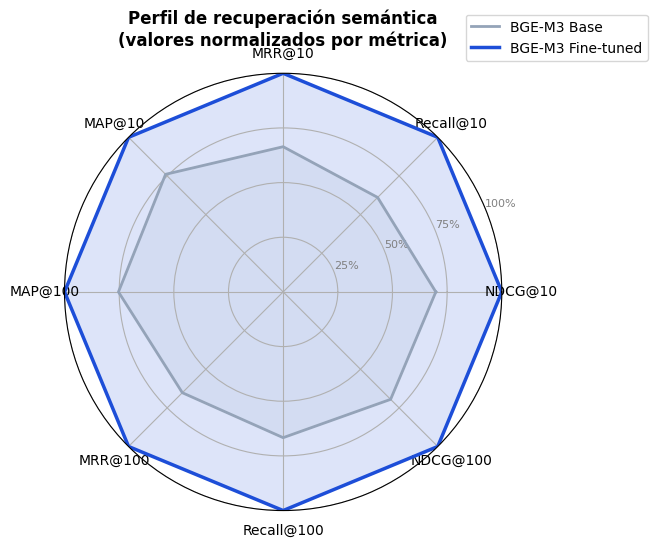

✓ radar_chart.png


In [ ]:
radar_metricas = ["NDCG@10","Recall@10","MRR@10","MAP@10",
                  "MAP@100","MRR@100","Recall@100","NDCG@100"]
N = len(radar_metricas)

base_r  = [base_metrics.get(m, 0)       for m in radar_metricas]
final_r = [ft_final_metrics.get(m, 0)   for m in radar_metricas]

# Normalizar por el máximo entre ambos modelos
maxvals = [max(base_r[i], final_r[i]) for i in range(N)]
base_r  = [v/m if m > 0 else 0 for v, m in zip(base_r,  maxvals)]
final_r = [v/m if m > 0 else 0 for v, m in zip(final_r, maxvals)]

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]
base_r  += base_r[:1]
final_r += final_r[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

ax.plot(angles, base_r,  linewidth=2, color=C_BASE,  label='BGE-M3 Base')
ax.fill(angles, base_r,  alpha=0.10, color=C_BASE)
ax.plot(angles, final_r, linewidth=2.5, color=C_FINAL, label='BGE-M3 Fine-tuned')
ax.fill(angles, final_r, alpha=0.15, color=C_FINAL)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metricas, size=10)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['25%', '50%', '75%', '100%'], size=8, color='gray')
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=10)
ax.set_title("Perfil de recuperación semántica\n"
             "(valores normalizados por métrica)",
             fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig("/content/radar_chart.png", dpi=150, bbox_inches='tight')
plt.show()
print("✓ radar_chart.png")

## 11. Gráfico 5 — Heatmap de métricas

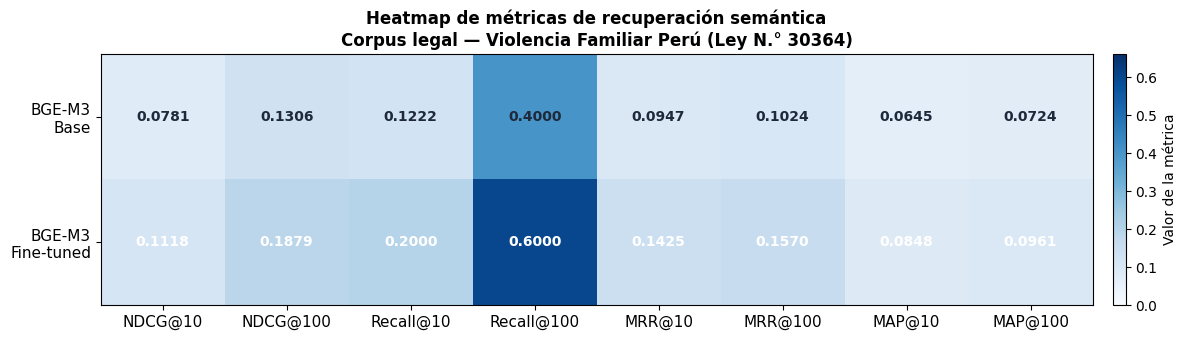

✓ heatmap.png


In [ ]:
modelos    = ['BGE-M3\nBase', 'BGE-M3\nFine-tuned']
metricas_h = ["NDCG@10","NDCG@100","Recall@10","Recall@100",
              "MRR@10","MRR@100","MAP@10","MAP@100"]

data = np.array([
    [base_metrics.get(m, 0)       for m in metricas_h],
    [ft_final_metrics.get(m, 0)   for m in metricas_h],
])

fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(data, cmap='Blues', aspect='auto',
               vmin=0, vmax=data.max() * 1.1)

ax.set_xticks(range(len(metricas_h)))
ax.set_xticklabels(metricas_h, fontsize=11)
ax.set_yticks(range(len(modelos)))
ax.set_yticklabels(modelos, fontsize=11)

for i in range(len(modelos)):
    for j in range(len(metricas_h)):
        val   = data[i, j]
        color = 'white' if val > data[:, j].mean() else '#1e293b'
        ax.text(j, i, f'{val:.4f}',
                ha='center', va='center',
                fontsize=10, fontweight='bold', color=color)

plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02,
             label='Valor de la métrica')
ax.set_title("Heatmap de métricas de recuperación semántica\n"
             "Corpus legal — Violencia Familiar Perú (Ley N.° 30364)",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig("/content/heatmap.png", dpi=150, bbox_inches='tight')
plt.show()
print("✓ heatmap.png")

## 12. Gráfico 6 — Análisis por métrica (subplots)

/tmp/ipykernel_567/3968634039.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(modelos_x, fontsize=9)
/tmp/ipykernel_567/3968634039.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(modelos_x, fontsize=9)
/tmp/ipykernel_567/3968634039.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(modelos_x, fontsize=9)
/tmp/ipykernel_567/3968634039.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(modelos_x, fontsize=9)
/tmp/ipykernel_567/3968634039.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

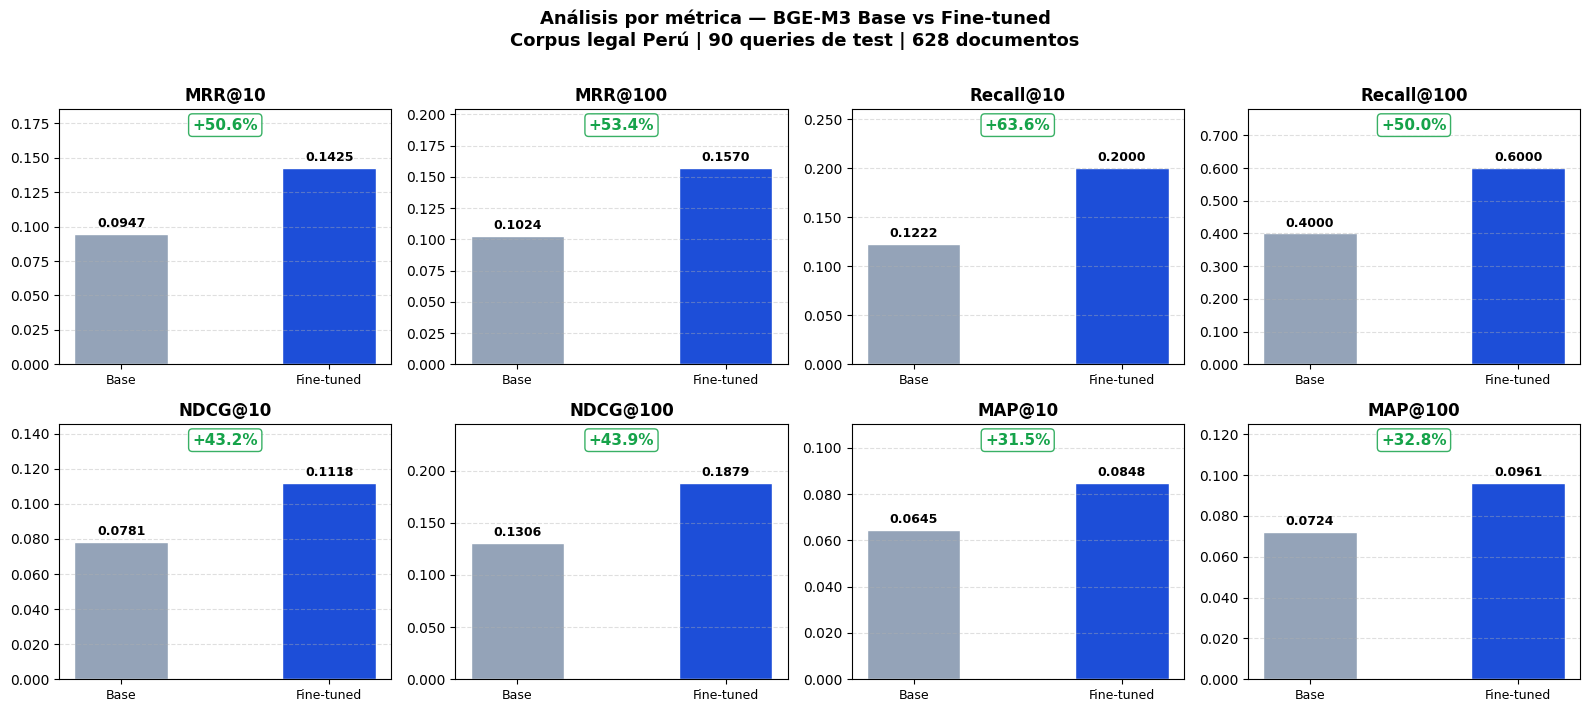

✓ per_metric_analysis.png


In [ ]:
metricas_sub = ["MRR@10","MRR@100","Recall@10","Recall@100",
                "NDCG@10","NDCG@100","MAP@10","MAP@100"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for ax, m in zip(axes, metricas_sub):
    b  = base_metrics.get(m, 0)
    ff = ft_final_metrics.get(m, 0)

    modelos_x = ['Base', 'Fine-tuned']
    vals      = [b, ff]
    cols      = [C_BASE, C_FINAL]

    bars = ax.bar(modelos_x, vals, color=cols,
                  edgecolor='white', width=0.45)

    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(vals)*0.02,
                f'{val:.4f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')

    mejora = ((ff - b) / b * 100) if b > 0 else 0
    color_txt = C_POS if mejora >= 0 else C_NEG
    ax.text(0.5, 0.92, f'{mejora:+.1f}%',
            transform=ax.transAxes,
            ha='center', fontsize=11, fontweight='bold',
            color=color_txt,
            bbox=dict(boxstyle='round,pad=0.25',
                      facecolor='white', edgecolor=color_txt, alpha=0.85))

    ax.set_title(m, fontsize=12, fontweight='bold')
    ax.set_ylim(0, max(vals) * 1.3)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_xticklabels(modelos_x, fontsize=9)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

plt.suptitle("Análisis por métrica — BGE-M3 Base vs Fine-tuned\n"
             "Corpus legal Perú | 90 queries de test | 628 documentos",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("/content/per_metric_analysis.png", dpi=150, bbox_inches='tight')
plt.show()
print("✓ per_metric_analysis.png")

## 13. Guardar todo en Drive

In [ ]:
import shutil

DRIVE_RESULTS = DRIVE_BASE / "resultados"
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

graficos = [
    "loss_curve.png",
    "metrics_comparison.png",
    "improvement_pct.png",
    "radar_chart.png",
    "heatmap.png",
    "per_metric_analysis.png",
]

print("Copiando gráficos a Drive...")
for g in graficos:
    src = Path(f"/content/{g}")
    if src.exists():
        shutil.copy2(src, DRIVE_RESULTS / g)
        print(f"  ✓ {g}")
    else:
        print(f"  ✗ {g} — no encontrado")

# JSON con todas las métricas
resultados_json = {
    "base":     base_metrics,
    "ft_final": ft_final_metrics,
    "mejora_pct": {
        m: round((ft_final_metrics.get(m,0) - base_metrics.get(m,0))
                 / base_metrics.get(m,1) * 100, 2)
        for m in base_metrics
    },
    "config": {
        "base_model":    "BAAI/bge-m3",
        "max_len":       2048,
        "epochs":        5,
        "batch_efectivo": 16,
        "train_samples": 810,
        "test_samples":  90,
        "corpus_size":   628,
        "neg_per_query": 10,
        "hard_negative_strategy": "BM25",
    }
}

json_path = DRIVE_RESULTS / "benchmark_final.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(resultados_json, f, indent=2, ensure_ascii=False)

print(f"\n✓ JSON guardado: {json_path}")
print(f"✓ Todo en: {DRIVE_RESULTS}")

Copiando gráficos a Drive...
  ✓ loss_curve.png
  ✓ metrics_comparison.png
  ✓ improvement_pct.png
  ✓ radar_chart.png
  ✓ heatmap.png
  ✓ per_metric_analysis.png

✓ JSON guardado: /content/drive/MyDrive/bge-m3-legal-peru-2048/resultados/benchmark_final.json
✓ Todo en: /content/drive/MyDrive/bge-m3-legal-peru-2048/resultados
